# M1 – Vehicle MDO (all 12 steps)

Size a quadcopter for a 2.5 kg payload with the brief's models (eqs. 1–6 and the structure checks).
All the code lives in `src/m1_vehicle/`; this notebook calls it step by step and shows the numbers.
`python run_all.py --only m1` produces the same results files and figures without the notebook.

| Step | What | Code |
|---|---|---|
| 1 | Variables, bounds, constants | `model.py` |
| 2 | Objective: min take-off mass for a required radius | `mdo.py`, `target_radius.py` |
| 3 | Analysis eqs. 1–6, hand check | `model.py`, `verify.hand_check` |
| 4 | MDA as fixed point on mass + convergence plot | `model.mda`, `verify.mda_convergence` |
| 5 | Constraints | `mdo.Problem.g_from` |
| 6–7 | MDF and IDF, agreement within 1 % | `mdo.solve_mdf`, `mdo.solve_idf` |
| 8 | Finite-difference gradient check | `verify.gradient_check` |
| 9 | Active constraints, payload multiplier | `sensitivity.py` |
| 10 | Snap to catalogue parts, re-check | `catalogue.py` |
| 11 | 5 designs along the payload–radius trade-off | `run.py` |

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

from m1_vehicle.model import Params, VARS, UNITS, LB, UB, analyse, mda, mda_closed_form, evaluate
from m1_vehicle.mdo import Problem, solve_mdf, solve_idf, solve_max_radius, CON_NAMES
from m1_vehicle import verify, sensitivity, catalogue, target_radius
from m1_vehicle.run import design_wind, required_radii, BASELINE
from common import RESULTS, FIGURES
RESULTS.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)

## Step 1 – Problem set-up
Five continuous design variables with the brief's bounds. FM = 0.65 (constant, M1 only); it sits in
`Params.fm(D, T)` so M3 can swap in its surrogate, and `Params.m_plate` (0.25 kg) is where M2's plate mass goes.

In [2]:
p = Params()
pd.DataFrame({'variable': VARS, 'unit': UNITS, 'lower': LB, 'upper': UB})

,variable,unit,lower,upper
0,D,m,0.3500,0.8000
1,E,Wh,200.0000,2000.0000
2,d,m,0.0150,0.0400
3,t,m,0.0005,0.0025
4,V,m/s,8.0000,22.0000


In [3]:
{k: v for k, v in vars(p).items() if k != 'fm'} | {'FM': p.fm(0.5, 20.0)}

{'rho': 1.225,
 'n': 4,
 'm_pay': 2.5,
 'm_fixed': 0.6,
 'm_plate': 0.25,
 'e_b': 150.0,
 'dod': 0.8,
 'reserve': 0.15,
 'eta': 0.85,
 'P_av': 30.0,
 'CdA': 0.08,
 'V_tip': 110.0,
 'E_cf': 70000000000.0,
 'rho_cf': 1550.0,
 'sigma_allow': 200000000.0,
 't_hover': 60.0,
 'complex_safe': True,
 'FM': 0.65}

## Step 2 – Objective and the required radius
**Objective: minimise take-off mass for a required radius.** Maximising radius pushes D, E, d to their upper
bounds (the partner's 20 kg design), where hover thrust is 49 N per rotor, outside the 8–40 N range of the M3
FM oracle, and drone capex grows with MTOW (₹45,000 per kg). Min-mass also lets us generate a *family* of
designs by changing the required radius, which is what M4/M6 need.

**Required radius comes from the map.** Flight distances go around both no-fly zones (visibility-graph shortest
path). Each PHC's distance to its nearest candidate hub sets what a vehicle must reach.

**Headwind.** The brief's headwind model (out-and-back time 2LV/(V²−w²)) shrinks the radius by (1 − w²/V²).
We size for w = P90 of the hourly mean wind in flyable hours (gust < 14 m/s). The 15 % energy reserve in eq. (6) stays on top.

In [4]:
dist = target_radius.hub_phc_distances()
nearest = dist.min(axis=0).sort_values(ascending=False)
print('PHCs farthest from their nearest candidate hub (km):'); print(nearest.head(5).round(2).to_string())
cov = pd.DataFrame([dict(k_hubs=k, radius_km=r, hubs=' '.join(h)) for k in range(1, 6)
                    for r, h in [target_radius.min_cover_radius(dist, k)]])
cov.round(2)

PHCs farthest from their nearest candidate hub (km):
P17    18.31
P23    14.53
P05    13.04
P13    10.51
P16    10.31


,k_hubs,radius_km,hubs
0,1,36.89,H0
1,2,33.35,H4 H5
2,3,23.90,H1 H2 H4
3,4,19.68,H1 H2 H6 P09
4,5,18.31,H0 H1 H2 H3 H6


In [5]:
wind = design_wind()
targets = required_radii(dist, wind, p)
print(f'design headwind w = {wind:.2f} m/s')
pd.DataFrame([(k, R, why) for k, (R, why) in targets.items()], columns=['design', 'R_req_km', 'why'])

design headwind w = 6.40 m/s


,design,R_req_km,why
0,A light,10.0,"light end: reaches PHCs within 10 km of a hub,..."
1,B all-but-one,14.6,every PHC but P17 from its nearest candidate hub
2,C cover-all,18.4,every PHC from its nearest candidate hub (bott...
3,D 4-hub,19.7,"every PHC from only 4 hubs (H1, H2, H6, P09)"
4,E reach,22.7,longest radius any catalogue build reaches wit...


## Step 3 – Analysis, checked by hand
`hand_check` recomputes eqs. (1)–(6) with plain `math`, one line per equation, and solves the mass
equation in closed form (it is linear in m). The last row is the partner's max-radius design: the review found
R = 27.27 km there, not 29.49 km.

In [6]:
x_rev = np.array([0.8, 2000, 0.04, 0.0025, 22])
r = evaluate(x_rev)
print({k: round(float(r[k]), 3) for k in ['m', 'T_max', 'T_hover_loaded', 'T_hover_empty', 'P_hover_loaded', 'R_km', 'sigma_MPa', 'f1_Hz', 'f1_req_Hz']})
pd.DataFrame([dict(quantity=k, hand=v, code=float(r[k])) for k, v in verify.hand_check(x_rev).items()])

{'m': 20.149, 'T_max': 98.828, 'T_hover_loaded': 49.414, 'T_hover_empty': 43.283, 'P_hover_loaded': 2296.147, 'R_km': 27.274, 'sigma_MPa': 20.677, 'f1_Hz': 50.358, 'f1_req_Hz': 50.333}


,quantity,hand,code
0,m,20.148521,20.148521
1,P_hover_loaded,2296.146714,2296.146714
2,P_hover_empty,1887.743452,1887.743452
3,P_cruise_loaded,2007.181284,2007.181284
4,P_cruise_empty,1739.524738,1739.524738
5,R_km,27.274428,27.274428


## Step 4 – MDA: fixed-point iteration on mass
Guess m → T_max = 2mg/4 → motor mass → new m (eq. 1). Because eq. (1) is linear in m with slope
4 × 0.004 × 2g/4 = 0.078, each iteration cuts the error by ~13×, from any starting guess.

,m0,iterations_to_1e8,m_final,m_exact
0,1.0,10,11.182427,11.182427
1,10.0,9,11.182427,11.182427
2,40.0,10,11.182427,11.182427


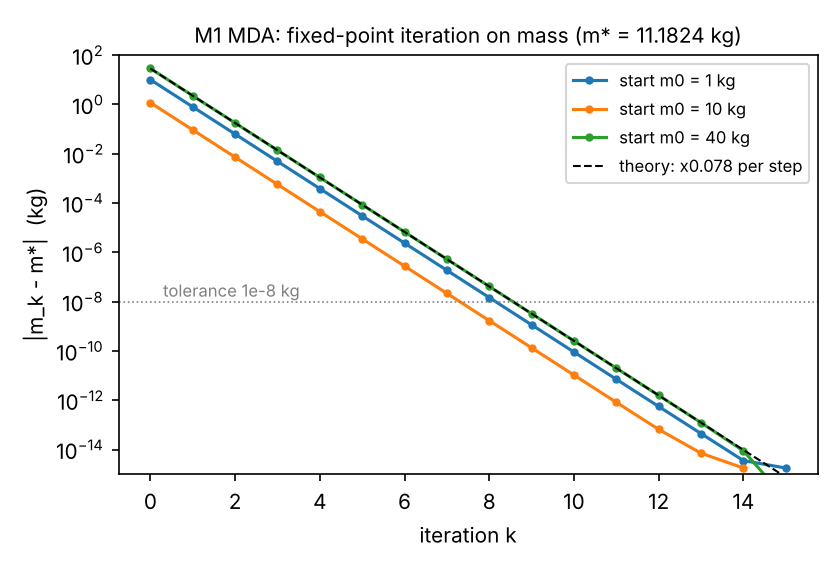

In [7]:
base = Problem(targets[BASELINE][0], wind, p)
best, runs = solve_mdf(base)
zb, xb = best.x, base.to_x(best.x)
conv = verify.mda_convergence(xb, FIGURES / 'm1_mda_convergence.png', p)
display(conv); display(Image(str(FIGURES / 'm1_mda_convergence.png')))

## Step 5 – Constraints (all written g ≥ 0, normalised by their limit)
Bending stress ≤ 200 MPa, tip deflection ≤ 0.01 L, f1 ≥ 1.15 × rotor frequency, d/t ≤ 40,
radius in design headwind ≥ required, T_max ≤ 100 N (largest catalogue motor), and loaded hover thrust ≤ 40 N /
empty ≥ 8 N so the M3 surrogate is never extrapolated.

In [8]:
pd.DataFrame({'constraint': base.con_names, 'g at baseline optimum': base.mdf_g(zb)}).round(5)

,constraint,g at baseline optimum
0,radius (wind-adjusted) >= required,-0.00000
1,bending stress <= 200 MPa,0.91939
2,tip deflection <= 0.01 L,0.79117
3,f1 >= 1.15 x rotor frequency,0.00000
4,d/t <= 40,0.40142
5,T_max <= 100 N (largest motor),0.45150
6,loaded hover thrust <= 40 N (M3 oracle),0.31438
7,empty hover thrust >= 8 N (M3 oracle),1.66171


## Steps 6–7 – MDF and IDF
**MDF:** the MDA runs inside every objective/constraint evaluation; the optimiser only sees x.
**IDF:** mass is a 6th optimiser variable and the consistency constraint m − m(x) = 0 replaces the MDA; every
IDF start is deliberately inconsistent (m = 10 kg). SLSQP, 8 Latin-hypercube starts each, complex-step gradients.

In [9]:
mi = verify.mdf_vs_idf({n: Problem(R, wind, p) for n, (R, _) in targets.items()})
mi[['design', 'R_req_km', 'm_MDF', 'm_IDF', 'm_rel_diff_pct', 'x_max_rel_diff_pct', 'MDF_starts_ok', 'IDF_starts_ok', 'MDF_iters', 'IDF_iters']]

,design,R_req_km,m_MDF,m_IDF,m_rel_diff_pct,x_max_rel_diff_pct,MDF_starts_ok,IDF_starts_ok,MDF_iters,IDF_iters
0,A light,10.0,7.195380,7.195380,3.732744e-11,2.391054e-06,8,8,11,14
1,B all-but-one,14.6,9.037217,9.037217,5.094840e-11,8.058637e-07,8,8,27,10
2,C cover-all,18.4,11.182427,11.182427,4.416101e-12,7.124923e-07,8,8,11,10
3,D 4-hub,19.7,12.137572,12.137572,1.745978e-11,1.061368e-08,8,8,8,11
4,E reach,22.7,15.250793,15.250793,1.995240e-11,7.477473e-09,8,8,10,10


## Step 8 – Gradient check
SLSQP gets complex-step derivatives (no step-size error). We compare them with forward and central finite
differences at h = 1e-4 and 1e-6, at the optimum and at a random point, with MDA tolerance 1e-12 and 1e-8.

scheme                                            central           forward         
step                                             0.000001 0.000100 0.000001 0.000100
mda_tol      point                 function                                         
1.000000e-12 baseline optimum      constraints g  1.2e-08  8.2e-07  9.4e-05  9.4e-03
                                   objective m    9.7e-10  2.3e-10  2.4e-07  2.4e-05
             random interior point constraints g  4.8e-09  5.0e-08  2.5e-06  2.5e-04
                                   objective m    1.5e-09  4.3e-10  3.2e-07  3.3e-05
1.000000e-08 baseline optimum      constraints g  4.4e-08  8.2e-07  9.3e-05  9.4e-03
                                   objective m    1.9e-09  2.2e-10  2.4e-07  2.4e-05
             random interior point constraints g  2.6e-09  5.0e-08  2.5e-06  2.5e-04
                                   objective m    7.5e-10  4.3e-10  3.3e-07  3.3e-05

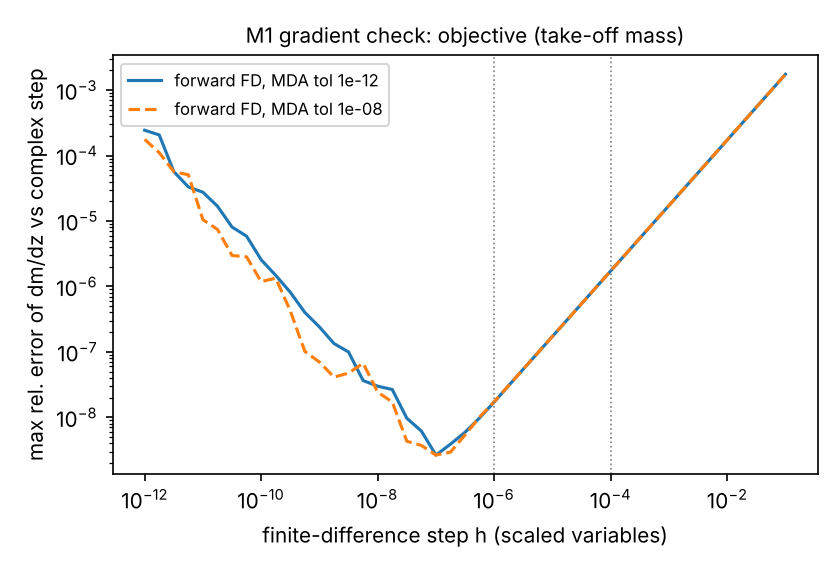

In [10]:
pts = {'baseline optimum': zb, 'random interior point': np.random.default_rng(1).uniform(0.2, 0.8, 5)}
gc = pd.concat([verify.gradient_check(base, pts),
                verify.gradient_check(Problem(base.R_req_km, wind, p, mda_tol=1e-8), pts)])
display(gc.pivot_table(index=['mda_tol', 'point', 'function'], columns=['scheme', 'step'], values='max_rel_err').map(lambda v: f'{v:.1e}'))
verify.gradient_step_sweep(base, pts['random interior point'], FIGURES / 'm1_gradient_check.png')
display(Image(str(FIGURES / 'm1_gradient_check.png')))

## Step 9 – Active constraints and the payload multiplier
KKT multipliers by least squares over the active set. By the envelope theorem
dm*/dm_pay = ∂L/∂m_pay and dm*/dR_req = ∂L/∂R_req; at fixed take-off mass, an extra 100 g of payload then
costs 0.1·(dm*/dm_pay)/(dm*/dR_req) km of radius. Re-solves check every number.

In [11]:
mult, resid = sensitivity.kkt_multipliers(base, zb)
print(f'KKT residual {resid:.1e}')
display(pd.DataFrame([(k, l) for k, (_, _, l) in mult.items()], columns=['active', 'multiplier']))
sens, _ = sensitivity.payload_sensitivity(base, zb)
pd.Series(sens).round(4)

KKT residual 1.2e-08


,active,multiplier
0,radius (wind-adjusted) >= required,1.238242
1,f1 >= 1.15 x rotor frequency,0.396188
2,D at upper bound,0.024340
3,d at upper bound,0.269162


kkt_residual                       0.0000
dm_dm_pay                          1.8924
dm_dR_req_km                       0.6730
km_lost_per_100g_multiplier        0.2812
dm_dm_pay_resolve                  1.8947
dm_dR_resolve                      0.6773
km_lost_per_100g_resolve           0.2825
R_at_mcap_base                    18.4000
R_at_mcap_plus100g                18.1175
km_lost_per_100g_frozen_design     0.1067
dtype: float64

## Step 10 – Snap to catalogue parts and re-check
Every combination of 1–4 identical packs (≤ 2000 Wh), 5 motors, 28 tubes, whole-inch props (14–31 in) and
V on a 0.5 m/s grid is evaluated with catalogue masses; the lightest one meeting **every** constraint (with the
chosen motor's own rating) is kept, then re-checked through the scalar code path.

In [12]:
s = catalogue.snap(base)
pd.Series({k: v for k, v in s.items()})

m                                                                      12.101047
m_empty                                                                 9.601047
T_max                                                                  59.355633
T_hover_loaded                                                         29.677817
T_hover_empty                                                          23.546567
P_hover_loaded                                                       1260.410887
P_hover_empty                                                          899.54814
P_cruise_loaded                                                      1216.251747
P_cruise_empty                                                        986.148964
E_use_Wh                                                                 664.224
R_km                                                                   20.537669
R_wind_km                                                              18.434612
sigma_MPa                   

## Step 11 – Design set along the payload–radius trade-off
Five required radii read off the map: 10 km (light), all PHCs but one, all PHCs from the nearest hub,
all PHCs from 4 hubs, and the longest radius a catalogue build reaches with hover thrust ≤ 40 N.
3 hubs (23.9 km) is out of reach for any design in the design headwind.

In [13]:
import m1_vehicle.run as m1run
ctx = m1run.run({})
d = ctx['m1_designs']
d[['design', 'R_req_km', 'm_continuous', 'm', 'battery', 'motor', 'tube', 'prop_in', 'V', 'R_km', 'R_wind_km',
   'T_max', 'motor_rating_N', 'T_hover_loaded', 'T_hover_empty', 'binding', 'all_feasible', 'drone_capex_inr']].round(3)

  design headwind (P90 of flyable hours): 6.40 m/s; plate mass 0.250 kg


  A light        R_req  10.0 km  m*  7.195 kg  snapped  7.495 kg (2xB6S-8K, M45, CF40x1.0, 26 in, V 15.5)


  B all-but-one  R_req  14.6 km  m*  9.037 kg  snapped  9.680 kg (1xB6S-27K, M60, CF40x1.5, 29 in, V 17.0)


  C cover-all    R_req  18.4 km  m* 11.182 kg  snapped 12.101 kg (2xB6S-22K, M60, CF40x1.5, 27 in, V 20.0)


  D 4-hub        R_req  19.7 km  m* 12.138 kg  snapped 13.345 kg (3xB6S-16K, M80, CF40x2.0, 30 in, V 20.5)


  E reach        R_req  22.7 km  m* 15.251 kg  snapped 16.260 kg (3xB6S-22K, M80, CF40x2.5, 31 in, V 21.0)
  verification: MDA convergence, hand check, gradients, MDF vs IDF


       design    m_MDF    m_IDF  m_rel_diff_pct
      A light  7.19538  7.19538             0.0
B all-but-one  9.03722  9.03722             0.0
  C cover-all 11.18243 11.18243             0.0
      D 4-hub 12.13757 12.13757             0.0
      E reach 15.25079 15.25079             0.0
  active at baseline: radius (wind-adjusted) >= required, f1 >= 1.15 x rotor frequency, D at upper bound, d at upper bound  (KKT residual 1.2e-08)
  payload: 0.281 km lost per extra 100 g at fixed MTOW (re-solve 0.283); +189 g MTOW per 100 g payload at fixed radius


,design,R_req_km,m_continuous,m,battery,motor,tube,prop_in,V,R_km,R_wind_km,T_max,motor_rating_N,T_hover_loaded,T_hover_empty,binding,all_feasible,drone_capex_inr
0,A light,10.0,7.195,7.495,2xB6S-8K,M45,CF40x1.0,26,15.5,12.129,10.061,36.762,45.0,18.381,12.250,d/t <= 40,True,537261.840
1,B all-but-one,14.6,9.037,9.680,1xB6S-27K,M60,CF40x1.5,29,17.0,17.041,14.626,47.482,60.0,23.741,17.610,radius (wind-adjusted) >= required,True,635611.512
2,C cover-all,18.4,11.182,12.101,2xB6S-22K,M60,CF40x1.5,27,20.0,20.538,18.435,59.356,60.0,29.678,23.547,radius (wind-adjusted) >= required,True,744547.093
3,D 4-hub,19.7,12.138,13.345,3xB6S-16K,M80,CF40x2.0,30,20.5,21.829,19.701,65.457,80.0,32.729,26.597,radius (wind-adjusted) >= required,True,800524.448
4,E reach,22.7,15.251,16.260,3xB6S-22K,M80,CF40x2.5,31,21.0,25.054,22.727,79.755,80.0,39.878,33.746,radius (wind-adjusted) >= required,True,931699.231


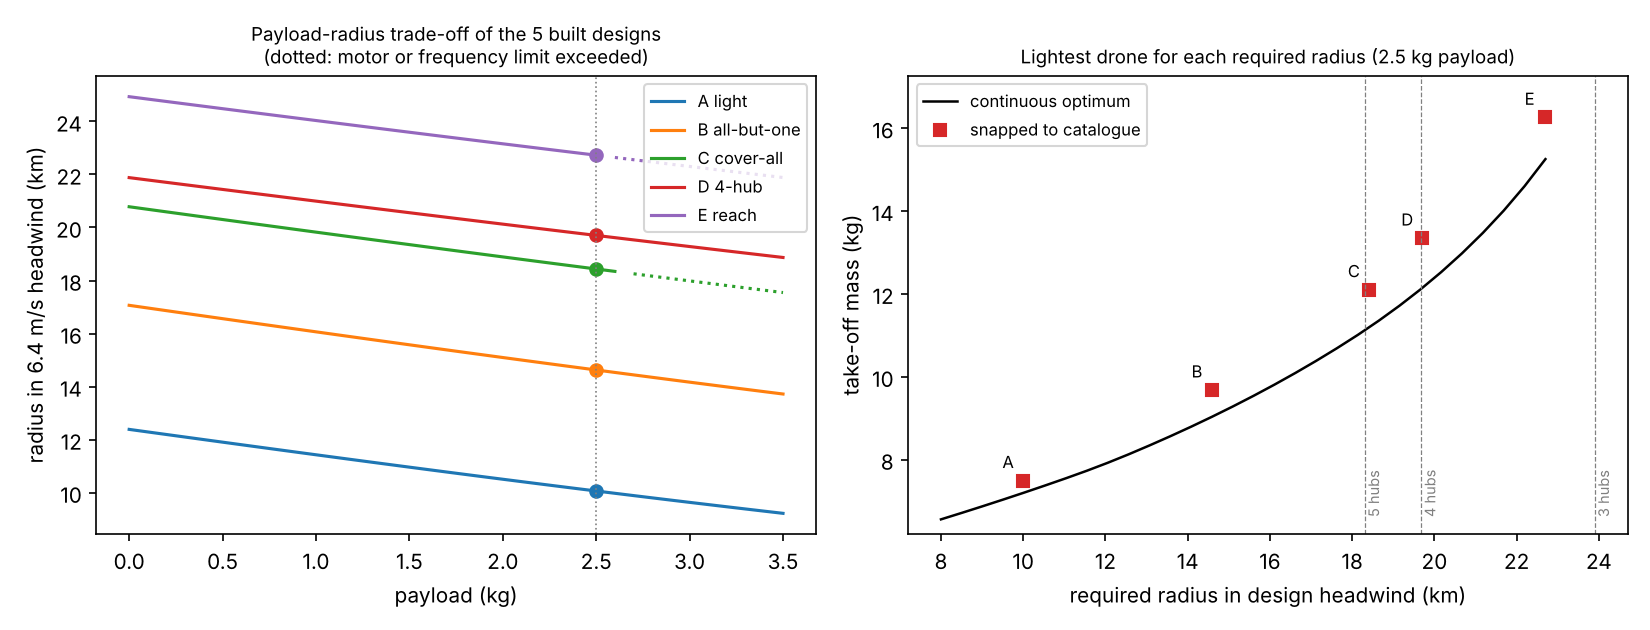

In [14]:
display(Image(str(FIGURES / 'm1_tradeoff.png')))